# Machine Learning in Python - Project 

Due Friday, December 4th 2026, by 4 pm.

**Maciek's everything file**

## Setup

*Install any packages here, define any functions if needed, and load data.*

In [37]:
# Add any additional libraries or submodules below

# Data libraries
import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA


In [38]:
# Load data  
df_avg = pd.read_csv("avg_river_levels.csv")
df_min = pd.read_csv("min_river_levels.csv")
df_max = pd.read_csv("max_river_levels.csv")
df_locs = pd.read_csv("monitoring_locations.csv")

In [39]:
def count_bad_measurements(df):

    date_cols = df.columns[3:]

    data = df[date_cols].apply(
        pd.to_numeric, errors="coerce"
    )

    data.columns = pd.to_datetime(date_cols, dayfirst=True)

    # Same date preprocessing
    data = data.sort_index(axis=1)

    all_dates = pd.date_range(
        start=data.columns.min(),
        end=data.columns.max(),
        freq="D"
    )

    data = data.reindex(columns=all_dates)

    # Remove first 908 dates
    data = data.iloc[:, 908:]

    # Count extreme observations
    above = (data > 20).sum().sum()
    below = (data < -20).sum().sum()
    total = above + below

    return above, below, total


for name, df in [
    ("Average", df_avg),
    ("Minimum", df_min),
    ("Maximum", df_max)
]:

    above, below, total = count_bad_measurements(df)

    print(f"\n{name} water levels:")
    print(f"  Above 40: {above}")
    print(f"  Below -40: {below}")
    print(f"  Total extreme observations: {total}")


Average water levels:
  Above 40: 2516
  Below -40: 36
  Total extreme observations: 2552

Minimum water levels:
  Above 40: 2451
  Below -40: 54
  Total extreme observations: 2505

Maximum water levels:
  Above 40: 2528
  Below -40: 7
  Total extreme observations: 2535


In [3]:
df_avg.head()

,County,Station_Name,Observation_ID,05/10/2014,06/10/2014,07/10/2014,08/10/2014,09/10/2014,10/10/2014,13/10/2014,...,29/09/2026,30/09/2026,01/10/2026,02/10/2026,03/10/2026,04/10/2026,05/10/2026,06/10/2026,07/10/2026,08/10/2026
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.133,0.152,0.169,0.143,0.136,0.130,0.126,0.120,0.120,0.120
1,aberdeenshire,"Dee (Grampian), Mar Lodge",aberdeenshire__dee-grampian-mar-lodge__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.721,0.971,0.849,0.799,0.861,0.752,0.727,0.695,0.677,0.669
2,aberdeenshire,"Dee (Grampian), Park",aberdeenshire__dee-grampian-park__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.934,0.973,1.264,0.990,1.054,0.988,0.918,0.887,0.854,0.836
3,aberdeenshire,"Dee (Grampian), Polhollick",aberdeenshire__dee-grampian-polhollick__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.483,0.704,0.683,0.530,0.676,0.530,0.496,0.460,0.438,0.427
4,aberdeenshire,"Dee (Grampian), Woodend",aberdeenshire__dee-grampian-woodend__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.578,0.700,0.861,0.645,0.739,0.642,0.583,0.547,0.514,0.495


# Introduction

*This section should include a brief introduction to the task and the data (assume this is a report you are delivering to a professional body (e.g. Scottish Government)).*

*State which supervised learning question you are answering.*

*Briefly outline the approaches being used (for both the clustering and your chosen supervised learning task) and the conclusions that you are able to draw.*

# Exploratory Data Analysis and Feature Engineering

*Include a detailed discussion of the data with a particular emphasis on the features of the data that are relevant for the subsequent modeling. Including visualisations of the data is strongly encouraged - all code and plots must also be described in the write up. Think carefully about whether each plot needs to be included in your final draft and the appropriate type of plot and summary for each variable type - your report should include figures but they should be as focused and impactful as possible.*

*You should also split your data into training and testing sets, ideally before you look too much into the features and relationships with the target, as discussed throughout the course.*

*Additionally, this section should also motivate and describe any preprocessing / feature engineering of the data. Pipelines should be used, and feature engineering steps that are performed as part of an sklearn pipeline should be implemented in the following section.*

*All code and figures should be accompanied by text that provides an overview / context to what is being done or presented.*

Main observations:
- For the first 900 days 390 stations have NO observations, so we will exclude this period from our data set.
- Only 22 stations have tidal observations 
- For the rest of the dataset we will add any missing dates (as NaNs) and make sure all dates are in chronological order
- We will interpolate the days when there is only a single day missing as an arithmetic avergae of adjecent days (problem: using future data and potentially missing short lived extreme water events so maybe not)
- We will keep all the other NaNs as they are, becasue it is easier to deal with NaN values than days that are not consecutive
- For the clustering problem we will create new features because raw water levels are not very useful and will transpose the matrix to have dates as rows as this is more convineinet for Pandas
- For the classification we will define "possible flood event" as one that is 95 or 99 quartile of the data for that station (using train split)
- Problem with regression: how to predict 90 days in advance? Not sure, I would lean towards doing the classification task
- Define a function that computes number of valid weeks (concequitive 7 days) and split roughly 80/20 so that both test and train have similar number of good sequences


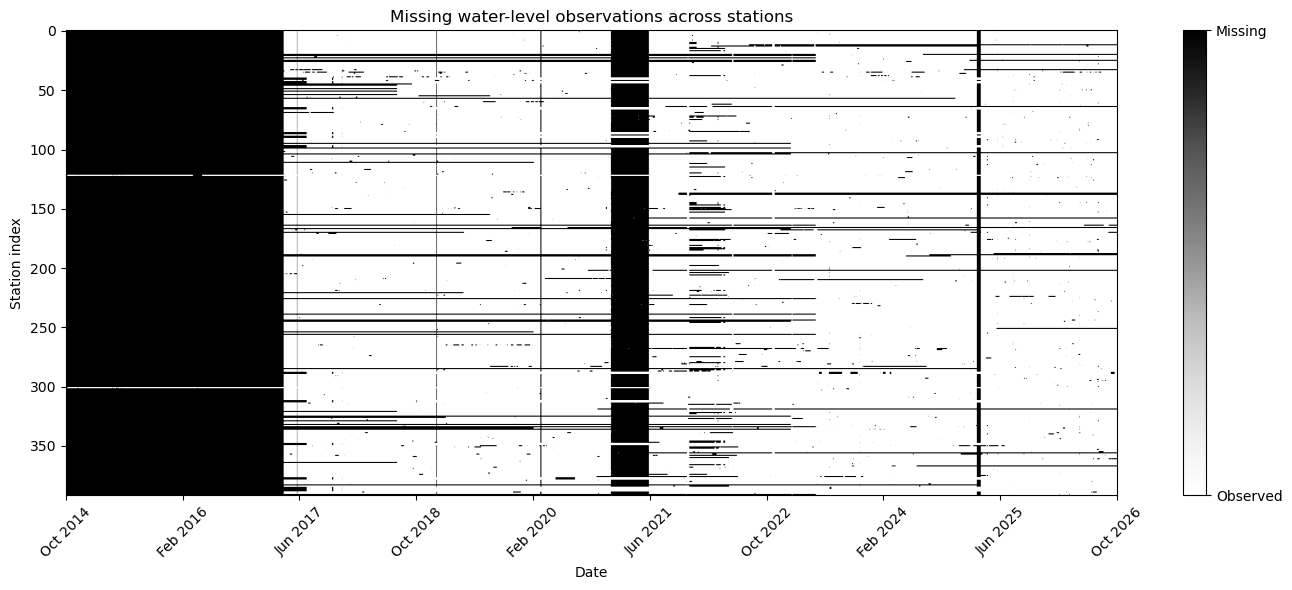

In [48]:
# Investigating the missing observations across different stations

# Select date columns
date_cols = df_avg.columns[3:]

data = df_avg[date_cols].apply(pd.to_numeric, errors="coerce")  # Make sure that the data has numerical values or NaN for missing values

# Convert columns to dates
data.columns = pd.to_datetime(date_cols, dayfirst=True)

# Sort chronologically and insert missing dates
data = data.sort_index(axis=1)

all_dates = pd.date_range(
    start=data.columns.min(),
    end=data.columns.max(),
    freq="D"
)

# If the date does NOT exist pandas creates a new column filled with NaN
data = data.reindex(columns=all_dates)

# Missing-data matrix: 1 = missing, 0 = observed
missing = data.isna().astype(int)

# Plot a heatmap
fig, ax = plt.subplots(figsize=(14, 6))

im = ax.imshow(
    missing,
    aspect="auto",
    cmap="Greys"
)

# Date labels
ticks = np.linspace(0, len(all_dates) - 1, 10, dtype=int)

ax.set_xticks(ticks)
ax.set_xticklabels(
    all_dates[ticks].strftime("%b %Y"),
    rotation=45
)

ax.set_xlabel("Date")
ax.set_ylabel("Station index")
ax.set_title("Missing water-level observations across stations")

# Colourbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_ticks([0, 1])
cbar.set_ticklabels(["Observed", "Missing"])

plt.tight_layout()
plt.show()

In [49]:
# Number of stations missing on each date
missing_count = data.isna().sum(axis=0)

# Dates where at least 50% of stations have missing observations
bad = missing_count >= 0.5 * len(data)

gaps = []
start = None

for i, value in enumerate(list(bad) + [False]):

    if value and start is None: # If we are on a bad date and are not inside a period
        start = i

    elif not value and start is not None: # If we at good date and we WERE in a period
        end = i - 1

        if end - start + 1 >= 5:  # Make it so we record ONLY gaps of length AT LEAST 5
            gaps.append([
                start,
                end,
                end - start + 1,
                missing_count.iloc[start:end+1].min()
            ])

        start = None

shared_gaps = pd.DataFrame(
    gaps,
    columns=["start_col", "end_col", "length", "min_missing_stations"]
)

shared_gaps = shared_gaps.sort_values("length", ascending=False)

print(shared_gaps.to_string(index=False))

 start_col  end_col  length  min_missing_stations
         0      907     908                   390
      2272     2430     159                   241
      3798     3814      17                   366
      1978     1982       5                   366


We decide to delete the first 908 dates since only 2 stations have ANY observations there.

In [45]:
# Data preprocessing
# Data preprocessing
def prepare_cluster(df):

    date_cols = df.columns[3:]

    data = df[date_cols].apply(
        pd.to_numeric, errors="coerce"
    )

    # Replace observations with |value| > 40 with NaN
    data = data.mask(data.abs() > 30)

    data.columns = pd.to_datetime(date_cols, dayfirst=True)

    data = data.sort_index(axis=1)

    all_dates = pd.date_range(
        start=data.columns.min(),
        end=data.columns.max(),
        freq="D"
    )

    data = data.reindex(columns=all_dates)

    # Remove the first 908 dates
    data = data.iloc[:, 908:]

    return data.T

# Prepare the data for our model
avg = prepare_cluster(df_avg)
minimum = prepare_cluster(df_min)
maximum = prepare_cluster(df_max)

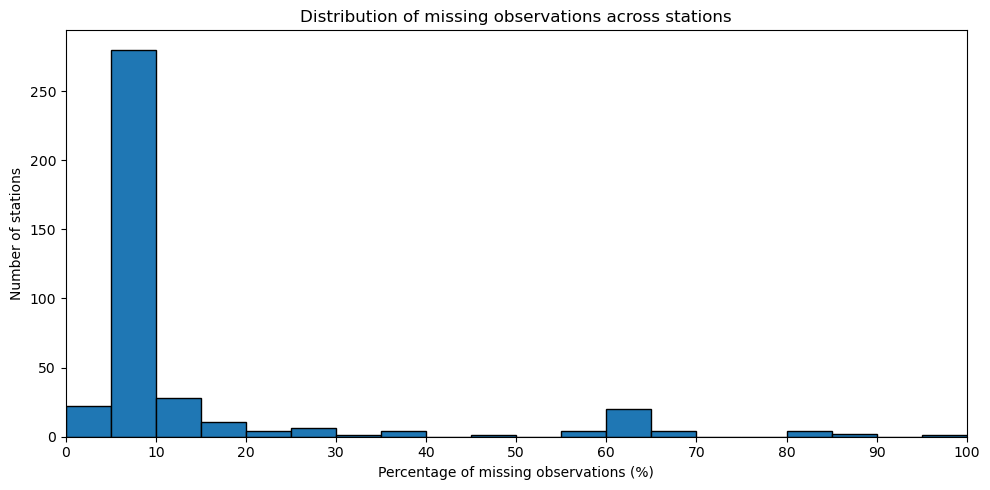

In [41]:
# After deleting the first 908 dates

# Calculate missing percentage for each station
missing_percentage = avg.isna().mean() * 100

plt.figure(figsize=(10, 5))

plt.hist(
    missing_percentage,
    bins=np.arange(0, 105, 5),
    edgecolor="black"
)

plt.xlabel("Percentage of missing observations (%)")
plt.ylabel("Number of stations")
plt.title("Distribution of missing observations across stations")

plt.xticks(np.arange(0, 101, 10))
plt.xlim(0, 100)

plt.tight_layout()
plt.show()

In [42]:
# Count the number of stations taht have tidal observations

n_tidal = df_avg.iloc[:, 2].str.contains("tidal", case=False, na=False).sum()

print("Number of tidal stations:", n_tidal)

Number of tidal stations: 12


In [46]:
# Define the features we want to use for the clustering problem 

# Interquartile range
iqr = avg.quantile(0.75) - avg.quantile(0.25)

# Upper-tail intensity
tail = (
    (avg.quantile(0.99) - avg.quantile(0.50))
    / iqr.where(iqr > 1e-8)
)

# Lower-tail intensity
tail_l = (
    (avg.quantile(0.50) - avg.quantile(0.01))
    / iqr.where(iqr > 1e-8)
)

# Within-day variability (where to account for possible NaN values)
daily_range = (maximum - minimum).where(maximum >= minimum)
R = daily_range.median()

# Daily changes
D = avg.diff().abs().median()

# Daily qutocorrelation
A1 = avg.corrwith(avg.shift(1))

# Weekly autocorrelation
AW = avg.corrwith(avg.shift(7))

# Monthly autocorrelation
AM = avg.corrwith(avg.shift(30))


# 7. Seasonal variation
first_half = avg[avg.index.month.isin([1, 2, 3, 4, 5, 6])].median()
second_half = avg[avg.index.month.isin([7, 8, 9, 10, 11, 12])].median()

S = first_half - second_half

# Construct feature matrix
X_cluster = pd.DataFrame({
    "IQR": iqr,
    "Upper_tail": tail,
    "Daily_range": R,
    "Daily_change": D,
    "Autocorr_1": A1,
    # "Autocorr_W": AW,
    # "Autocorr_M": AM,
    "Seasonality": S,
    "Lower_tail": tail_l,

})

print(X_cluster.head())
print("\nMissing features:")
print(X_cluster.isna().sum())


       IQR  Upper_tail  Daily_range  Daily_change  Autocorr_1  Seasonality  \
0  0.22875    3.666142       0.0130         0.009    0.909595       0.0345   
1  0.19725    3.219265       0.0500         0.030    0.747529      -0.0110   
2  0.39725    3.747111       0.0565         0.042    0.840708       0.0350   
3  0.24675    2.993110       0.0500         0.033    0.795250       0.0035   
4  0.34500    3.043188       0.0510         0.039    0.833367       0.0345   

   Lower_tail  
0    0.865574  
1    0.887199  
2    0.813090  
3    0.960932  
4    0.919275  

Missing features:
IQR             0
Upper_tail      0
Daily_range     0
Daily_change    0
Autocorr_1      0
Seasonality     0
Lower_tail      0
dtype: int64


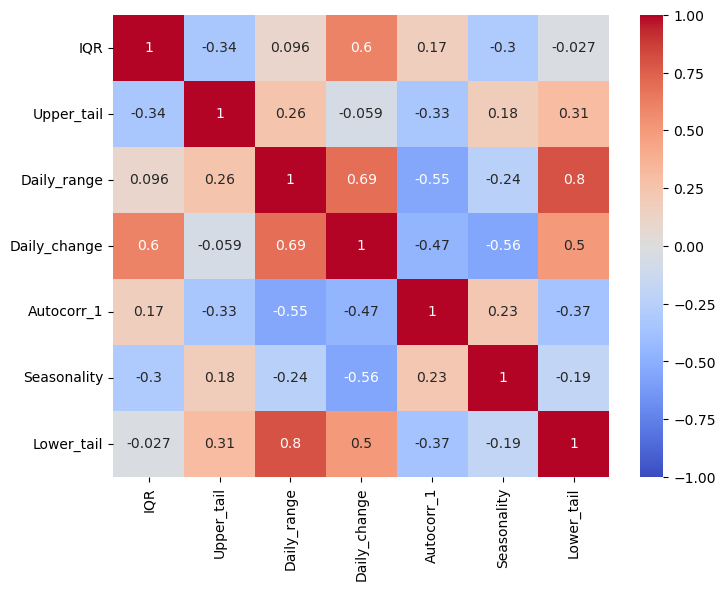

In [47]:
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(
    X_cluster.corr(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.show()

# Model Fitting and Tuning

*In this section you should detail and motivate your choice of model and describe the process used to refine, tune, and fit that model. You are encouraged to explore different models but you should NOT include a detailed narrative or code of all of these attempts. At most this section should very briefly mention the methods explored and why they were rejected - most of your effort should go into describing the final model you are using and your process for tuning and validating it.*

*This section should include the full implementation of your final model, including all necessary validation. All displayed figures should be described and referenced in the text.*

*You should also include a baseline model of your choice and provide a comparison of your model with the baseline model on the test data. You should briefly describe the baseline model considered.*

## Clustering problem

In this subsection we explore the problem of clustering the river monitoring stations. This is an unsupervised machine learning task, where based on some selected features we try to group together stations with similar properties. In this project we explore K-means ++ and hierarchical clustering. 

The first step of building a clustering model is to select sensible features that allow the data to be clustered. In the datasets we are given we are given stations and their respective mean, max and min water levels. Since these are on dependent on a specific river and its depth, these measures are not particualry well suited for the clustering proble, so we look for other possible measures. One such measure that immediately comes to mind is to try and quantify the variability of the water level at each station. The simplest way to do that is to look at the range of the data (i.e max - min) however that approach is easily skewed by outliers. As an example of that we can think of a river that has one flood event in the history. Using the range feature it might classify it together with rivers that have big water level variabilty, which would not be a good assigment. Similar problem goes for using standard deviation, which in this case is additionally amplified since we will later want to standardise the data. For that reason we believe that the interquartile range (IQR) is a good measure in this case, since it is resitant to outliers and will give a reliable measure of how variable the river is. Given that the risk of flooding is an important phenomenon we want to prevent we might also want to consider how extreme unusually high level are, which might help us identify stations where there is an often flooding occurence. On the flip side we might also want to look at how extreme unusually low level are, if we are looking at potential draughts. We might also want to consider the within-day variability and daily changes. On a larger scale we might want to consider the autocorrelation between different logged values to understand whether the water level fluctuation happen on short- or long- timescales. We know that different season are characterised by different amounts of rainfall, so seasonality might also play an important part. Finally we might want to add a feature that measures unsually large within-day fluctuations to distinguish between river with persistent large daily fluctuations and occasional (but extreme) ones. 

It is desirable to transpose our data to have the dates as rows and stations as columns, since pandas is designed to perform time-series opertations along the row index. As discoverd in EDA there are certain dates missing from our data set, which we can add by using .asfreq("D") which ensures that there is a row for every calendar day between the first and last dates. It does it so by adding rows with NaN values for the missing dates. We also want to make sure that the time series data is encoded as a time variable and that it is in chronological order. 

As the next step we investigate the correlation between the features to potemntially disregard features that are higly correlated, which might skwe our clustering algorithm. We can see that all measures of autocorreality are highly correlated, so we decide to keep only the weekly correlation which gives us the most unique information compared to other features. After that we want to standardise our data, since we are mostly interested in the variability of water levels and not general values of water levels. We also need to choose an appropraiet amount of clusters which we do by analysing both the elbow method and the silhoutte score method. While the albow plot in this case is not particularly insightful we will focus more on the slihouette score. We obtain the higest score for 2 clusters wirh the score 0.6 and the seocnd best for 4 clusters wirh score 0.35. Therefore for our primary model we chose the one with 2 clusters. However, under further analysis we found that 2 clusters mainly separates stations with tidal observations from stations withour tidal observations. This is a very important discvoery and a good check that our clustering is performing well. However, since there is very few tidal stations compared to non-tidal ones we might also want to explore different sub-categories of statiosn within the non-tidal ones. For that reason we focus on the 3 cluster solution. We can analyse the mean feature values in each of the clusters. We can see that we still have almost all tidal stations in one clusters (cluster 1), while the other two clusters represent non-tidal observations. Both clusters 0 and 2 have very similar Daily_change, Autocorr_W and Seasonality, while the differences occur in other features. Cluster 0  has really small IQR, daily change, daily range, but relatively large upper tail. This might mean that this cluster is more prone to flooding, since it is generally stable but has a hight upper tail. On the other hand cluster 2 describes stations that are more variable from day to day

c:\Users\Maciek\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Maciek\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Maciek\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Maciek\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Wi

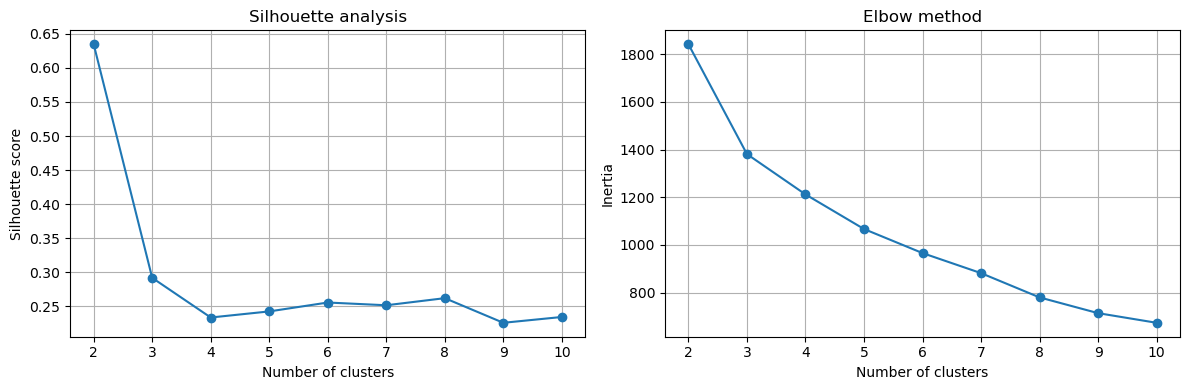

In [48]:
# Creating the pipeline and investigating the number of clusters

k_values = range(2, 11)

silhouette_scores = []
inertias = []

for k in k_values:

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("kmeans", KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=20,
            random_state=42
        ))
    ])

    labels = pipeline.fit_predict(X_cluster)

    X_scaled = pipeline.named_steps["scaler"].transform(X_cluster)

    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

    inertias.append(
        pipeline.named_steps["kmeans"].inertia_
    )


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_values, silhouette_scores, marker="o")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Silhouette score")
axes[0].set_title("Silhouette analysis")

axes[1].plot(k_values, inertias, marker="o")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Inertia")
axes[1].set_title("Elbow method")

for ax in axes:
    ax.grid()

plt.tight_layout()
plt.show()

In [49]:

pipeline3 = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(
        n_clusters=3,
        init="k-means++",
        n_init=20,
        random_state=42
    ))
])

labels3 = pipeline3.fit_predict(X_cluster)

X_clustered3 = X_cluster.copy()
X_clustered3["Cluster"] = labels3

pipeline2 = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(
        n_clusters=2,
        init="k-means++",
        n_init=20,
        random_state=42
    ))
])

labels2 = pipeline2.fit_predict(X_cluster)

X_clustered2 = X_cluster.copy()
X_clustered2["Cluster"] = labels2

c:\Users\Maciek\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Maciek\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


In [29]:
print(X_clustered2["Cluster"].value_counts().sort_index())
print("Cluster means:")
print(X_clustered2.groupby("Cluster").mean().round(3))

print("\nCluster medians:")
print(X_clustered2.groupby("Cluster").median().round(3))

Cluster
0    370
1     22
Name: count, dtype: int64
Cluster means:
           IQR  Upper_tail  Daily_range  Daily_change  Autocorr_1  \
Cluster                                                             
0        0.272       3.289        0.067         0.030       0.819   
1        0.292       4.662        2.824         0.103       0.547   

         Seasonality  Lower_tail  
Cluster                           
0             -0.023       0.959  
1             -0.070       4.254  

Cluster medians:
           IQR  Upper_tail  Daily_range  Daily_change  Autocorr_1  \
Cluster                                                             
0        0.239       3.125        0.040         0.027       0.833   
1        0.290       3.905        2.758         0.106       0.536   

         Seasonality  Lower_tail  
Cluster                           
0             -0.024       0.860  
1             -0.065       3.759  


In [50]:
print(X_clustered3["Cluster"].value_counts().sort_index())
print("Cluster means:")
print(X_clustered3.groupby("Cluster").mean().round(3))

print("\nCluster medians:")
print(X_clustered3.groupby("Cluster").median().round(3))

Cluster
0    224
1     20
2    148
Name: count, dtype: int64
Cluster means:
           IQR  Upper_tail  Daily_range  Daily_change  Autocorr_1  \
Cluster                                                             
0        0.191       3.710        0.029         0.018       0.820   
1        0.298       4.902        2.981         0.105       0.527   
2        0.392       2.625        0.140         0.048       0.820   

         Seasonality  Lower_tail  
Cluster                           
0              0.004       0.945  
1             -0.070       4.304  
2             -0.064       1.020  

Cluster medians:
           IQR  Upper_tail  Daily_range  Daily_change  Autocorr_1  \
Cluster                                                             
0        0.186       3.433        0.025         0.016       0.834   
1        0.292       4.016        2.874         0.107       0.531   
2        0.365       2.670        0.068         0.043       0.824   

         Seasonality  Lower_tail  
Clus

In [31]:
from sklearn.metrics import silhouette_samples

X_scaled = pipeline3.named_steps["scaler"].transform(X_cluster)

sil = silhouette_samples(
    X_scaled,
    labels3
)

print(
    pd.DataFrame({
        "Cluster": labels3,
        "Silhouette": sil
    }).groupby("Cluster").agg(
        ["mean", "median"]
    )
)

        Silhouette          
              mean    median
Cluster                     
0         0.305451  0.318641
1         0.510709  0.525638
2         0.237807  0.257076


In [51]:
silhouette_df = pd.DataFrame({
    "Cluster": labels3,
    "Silhouette": sil
})

print(
    silhouette_df.groupby("Cluster")["Silhouette"]
    .agg(
        Mean="mean",
        Median="median",
        Minimum="min",
        Negative_fraction=lambda x: (x < 0).mean()
    )
)

             Mean    Median   Minimum  Negative_fraction
Cluster                                                 
0        0.305451  0.318641  0.015104            0.00000
1        0.510709  0.525638  0.341327            0.00000
2        0.237807  0.257076 -0.017861            0.02027


In [33]:
# Reload original station information
df_info = pd.read_csv("avg_river_levels.csv")

# Attach 4-cluster labels to station information
results = df_info.loc[X_cluster.index, ["Observation_ID"]].copy()

results["Cluster"] = labels3

# Identify tidal stations
results["Tidal"] = (
    results["Observation_ID"]
    .str.contains("tidal-level", case=False, na=False)
)

# Count tidal and non-tidal stations in each cluster
print("Number of stations:")
print(pd.crosstab(
    results["Cluster"],
    results["Tidal"]
))

# Percentage of tidal stations within each cluster
print("\nPercentage within each cluster:")
print(
    (pd.crosstab(
        results["Cluster"],
        results["Tidal"],
        normalize="index"
    ) * 100).round(2)
)

Number of stations:
Tidal    False  True 
Cluster              
0          224      0
1           10     10
2          146      2

Percentage within each cluster:
Tidal     False  True 
Cluster               
0        100.00   0.00
1         50.00  50.00
2         98.65   1.35


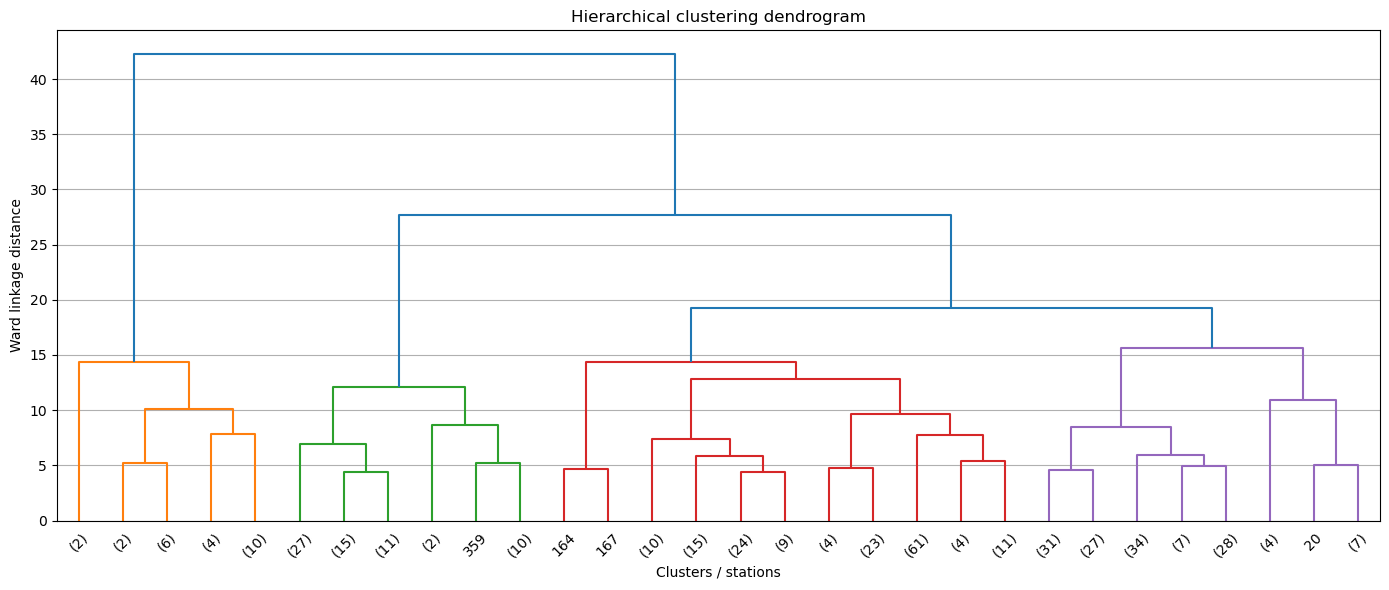

In [52]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler

# Standardise the same features used for K-means
X_scaled = StandardScaler().fit_transform(X_cluster)

# Hierarchical clustering using Ward's method
Z = linkage(X_scaled, method="ward")

# Plot dendrogram
plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    color_threshold=Z[-3, 2]  # Colour branches for approximately 4 clusters
)

plt.xlabel("Clusters / stations")
plt.ylabel("Ward linkage distance")
plt.title("Hierarchical clustering dendrogram")
plt.grid(axis="y")

plt.tight_layout()
plt.show()

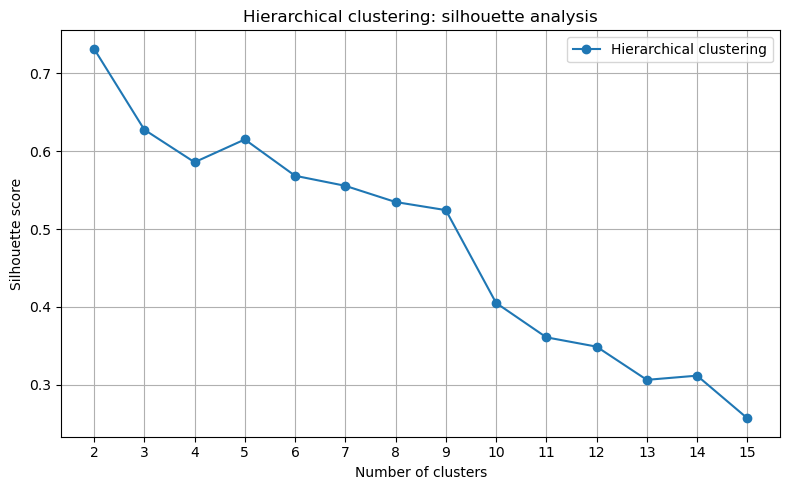

In [35]:
k_values = range(2, 16)

scores_hierarchical = []

for k in k_values:

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="average"
    )

    labels_h = model.fit_predict(X_scaled)

    scores_hierarchical.append(
        silhouette_score(X_scaled, labels_h)
    )

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    scores_hierarchical,
    marker="o",
    label="Hierarchical clustering"
)

plt.xlabel("Number of clusters")
plt.ylabel("Silhouette score")
plt.title("Hierarchical clustering: silhouette analysis")
plt.xticks(list(k_values))
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()

In [53]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Standardise the same features used for K-means
X_scaled = StandardScaler().fit_transform(X_cluster)

# Hierarchical clustering with 4 clusters
hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

labels_hierarchical = hierarchical.fit_predict(X_scaled)

# Add cluster labels to the original feature matrix
X_hierarchical = X_cluster.copy()
X_hierarchical["Cluster"] = labels_hierarchical

# Number of stations in each cluster
print(X_hierarchical["Cluster"].value_counts().sort_index())

# Cluster characteristics
print("\nCluster means:")
print(X_hierarchical.groupby("Cluster").mean().round(3))

print("\nCluster medians:")
print(X_hierarchical.groupby("Cluster").median().round(3))

Cluster
0    302
1     24
2     66
Name: count, dtype: int64

Cluster means:
           IQR  Upper_tail  Daily_range  Daily_change  Autocorr_1  \
Cluster                                                             
0        0.221       3.475        0.040         0.024       0.811   
1        0.286       4.520        2.700         0.099       0.556   
2        0.503       2.420        0.153         0.055       0.870   

         Seasonality  Lower_tail  
Cluster                           
0             -0.011       0.965  
1             -0.071       4.068  
2             -0.078       0.906  

Cluster medians:
           IQR  Upper_tail  Daily_range  Daily_change  Autocorr_1  \
Cluster                                                             
0        0.215       3.230        0.032         0.022       0.821   
1        0.289       3.885        2.726         0.103       0.540   
2        0.453       2.490        0.076         0.051       0.873   

         Seasonality  Lower_tail  
Clu

## Classification task


In [87]:
# Number of complete 7-day windows
# data_clean: stations as rows, dates as columns

valid = data_clean.notna().T.rolling(7).sum().eq(7)
valid &= data_clean.T.shift(-1).notna()

valid_windows = valid.sum()

# Combine statistics
station_quality = pd.DataFrame({
    "missing_percentage": missing_percentage,
    "valid_windows": valid_windows
})

print(
    station_quality[
        station_quality["missing_percentage"].between(80, 90)
    ].sort_values("missing_percentage")
)

NameError: name 'data_clean' is not defined

# Interpretation, Discussion & Conclusions

*In this section you should provide a general overview of your final clustering and of your final supervised learning model, its performance, and reliability. You should discuss what the implications of your models are in terms of the included features, estimated parameters and relationships, predictive performance, and anything else you think is relevant.*

*This should be written with a target audience of a government official, who understands the monitoring of river levels but may only have university level mathematics (not necessarily postgraduate statistics or machine learning). Your goal should be to highlight to this audience how your model can useful. You should also discuss potential limitations or directions of future improvement of your model.*

*Finally, you should include recommendations on factors that may influence the classification of flood events OR the prediction of future water levels (depending on which question you are answering), which may be useful for the government officials to improve their understanding of floods or water level forecasting, and potentially assist in the development of effective river management and interventions.*

*Keep in mind that a negative result, i.e. a model that does not work well predictively, that is well explained and justified in terms of why it failed will likely receive higher marks than a model with strong predictive performance but with poor or incorrect explanations / justifications.*

# Generative AI statement

*Include a statement on if and how generative AI was used in the project and report.*

# References

*Include a list of all references cited in the text.*

In [1]:
# Run the following to render to PDF
!jupyter nbconvert --to pdf project.ipynb

[NbConvertApp] Converting notebook project.ipynb to pdf
[NbConvertApp] Writing 29863 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 47131 bytes to project.pdf
